# 02 · Análise exploratória (EDA)

Antes de modelar, olhamos os dados de frente. Três perguntas guiam este notebook:

1. **Estrutura:** no longo prazo, o emprego em tecnologia cresce mais rápido que a economia?
2. **Ciclo:** o que está acontecendo agora (2022–2026)? A queda recente é inédita?
3. **Abrangência:** o padrão se repete fora dos EUA?

> **Núcleo tech (EUA)** = *Design de sistemas de computação e serviços relacionados* (NAICS 5415)
> \+ *Infraestrutura de computação, processamento de dados e hospedagem* (NAICS 518). Fonte: BLS/CES.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

from techdemand import config, data_sources as ds, features as ft, style

style.apply()
%matplotlib inline

panel = ds.fetch_fred_panel()
tech = ft.tech_employment(panel)
share = ft.tech_share(panel)
recessions = ft.recession_spans(panel["USREC"].loc["1990":])

def shade_recessions(ax):
    for start, end in recessions:
        ax.axvspan(start, end + pd.offsets.MonthEnd(0), color=style.TEXT_PRIMARY, alpha=0.07, lw=0)

## 1. Três décadas de emprego em tecnologia

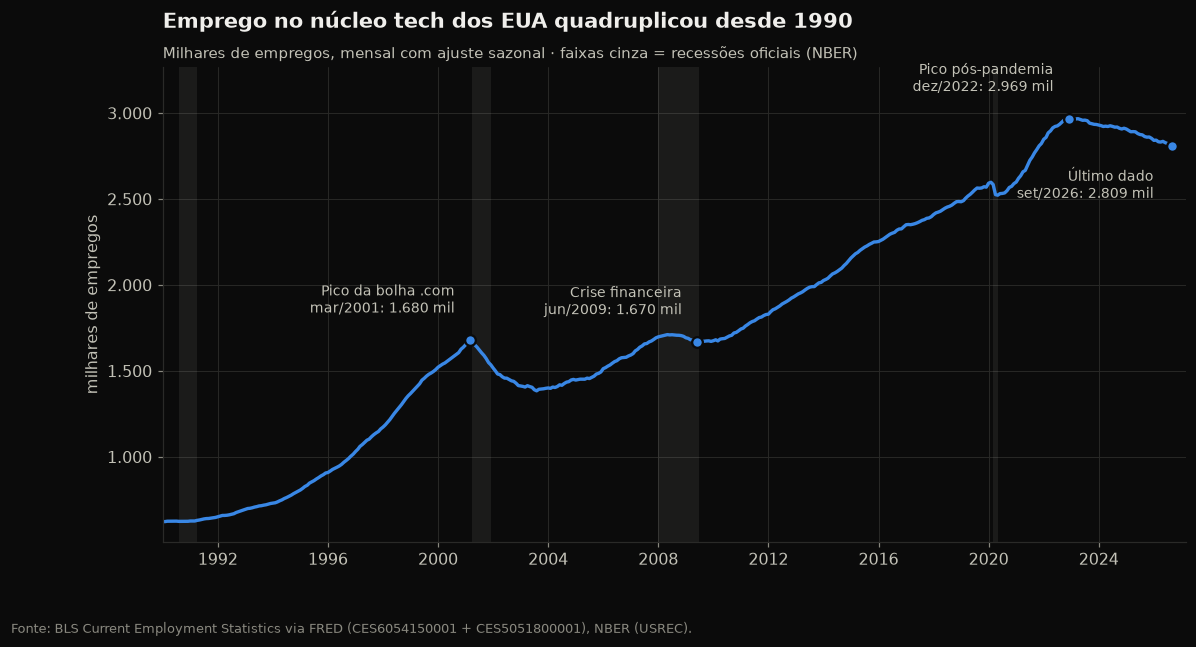

1990 → hoje: 623 → 2.809 mil (×4.5)
Variação desde o pico de dez/2022: -5.4%


In [2]:
fig, ax = plt.subplots(figsize=(12, 5.6))
shade_recessions(ax)
ax.plot(tech.index, tech, color=style.color_for("Núcleo tech"), lw=2.2)

peak_dotcom = tech.loc["2000":"2002"].idxmax()
peak_2022 = tech.loc["2021":].idxmax()
eventos = {
    peak_dotcom: "Pico da bolha .com",
    tech.loc["2008":"2010"].idxmin(): "Crise financeira",
    peak_2022: "Pico pós-pandemia",
    tech.index[-1]: "Último dado",
}
for d, txt in eventos.items():
    v = tech.loc[d]
    ax.plot(d, v, "o", color=style.color_for("Núcleo tech"), ms=7, mec=style.SURFACE, mew=1.5, zorder=5)
    offset = (-12, -34) if txt == "Último dado" else (-10, 18)
    ax.annotate(f"{txt}\n{style.fmt_month(d)}: {style.fmt_num(v)} mil", (d, v), xytext=offset,
                textcoords="offset points", ha="right", fontsize=9, color=style.TEXT_SECONDARY)

ax.set_title("Emprego no núcleo tech dos EUA quadruplicou desde 1990")
style.subtitle(ax, "Milhares de empregos, mensal com ajuste sazonal · faixas cinza = recessões oficiais (NBER)")
ax.set_ylabel("milhares de empregos")
style.thousands_axis(ax)
ax.set_ylim(top=tech.max() * 1.1)
ax.set_xlim(tech.index[0], tech.index[-1] + pd.DateOffset(months=6))
style.source(fig, "BLS Current Employment Statistics via FRED (CES6054150001 + CES5051800001), NBER (USREC).")
style.save(fig, "02_01_emprego_tech_longo_prazo")
plt.show()

queda = (tech.iloc[-1] / tech.loc[peak_2022] - 1) * 100
print(f"1990 → hoje: {style.fmt_num(tech.iloc[0])} → {style.fmt_num(tech.iloc[-1])} mil (×{tech.iloc[-1] / tech.iloc[0]:.1f})")
print(f"Variação desde o pico de {style.fmt_month(peak_2022)}: {queda:+.1f}%")

## 2. Crescimento estrutural: tech vs. economia

Comparar níveis absolutos engana. Abaixo, cada série é **reindexada para 1990 = 100**, e à direita
medimos a **participação do tech no emprego total** — um indicador que elimina o efeito do crescimento
geral da população e da economia.

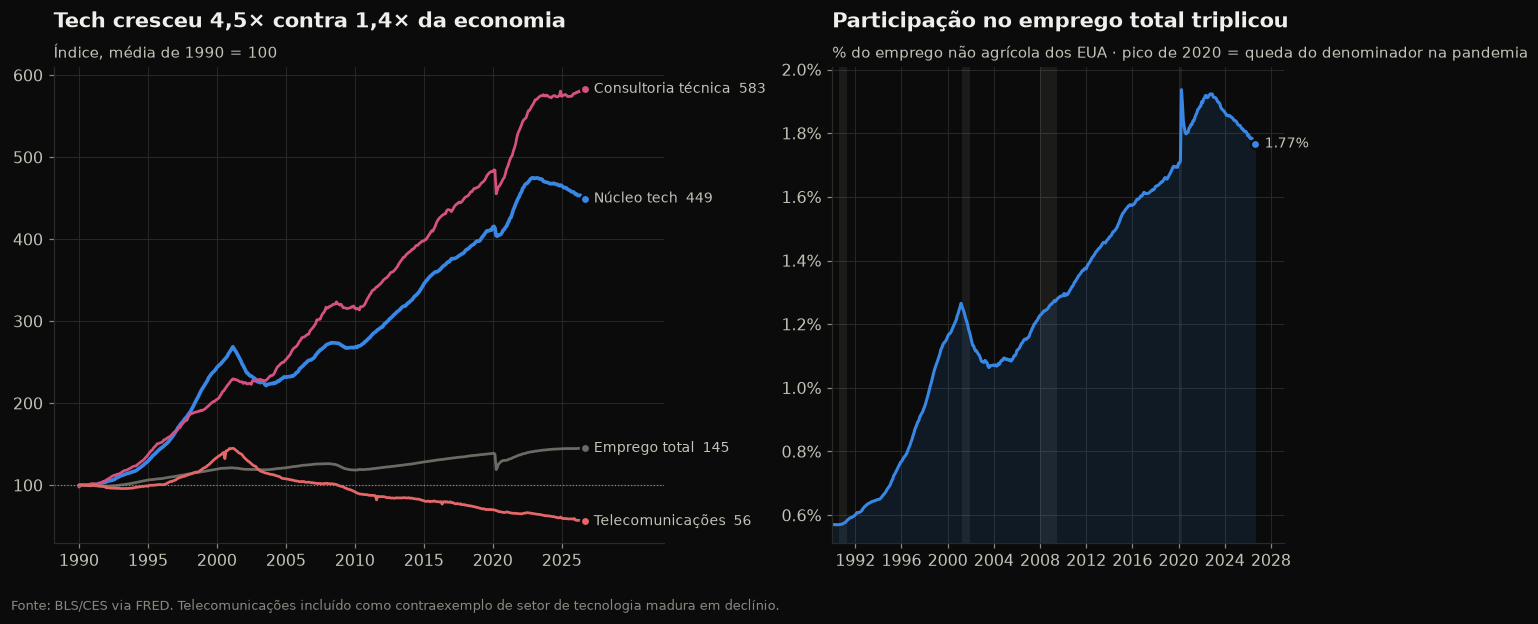

,CAGR tech (%)
1990–2000,9.68
2000–2010,0.76
2010–2019,4.56
2019–2025,2.13


In [3]:
series_cmp = {
    "Núcleo tech": tech,
    "Consultoria técnica": panel["CES6054160001"],
    "Emprego total": panel["PAYEMS"].loc["1990":],
    "Telecomunicações": panel["CES5051700001"],
}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.35, 1]})
for name, s in series_cmp.items():
    r = ft.rebase(s.dropna(), "1990")
    color = style.NEUTRAL if name == "Emprego total" else style.color_for(name)
    ax1.plot(r.index, r, color=color, lw=2.4 if name == "Núcleo tech" else 1.8)
    style.label_line_end(ax1, r.index[-1], r.iloc[-1], f"{name}  {r.iloc[-1]:.0f}", color)
ax1.axhline(100, color=style.TEXT_MUTED, lw=0.8, ls=":")
ax1.set_title("Tech cresceu 4,5× contra 1,4× da economia")
style.subtitle(ax1, "Índice, média de 1990 = 100")
ax1.set_xlim(right=pd.Timestamp("2032-06-01"))
ax1.set_xticks(pd.to_datetime([f"{y}-01-01" for y in range(1990, 2030, 5)]))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

shade_recessions(ax2)
ax2.plot(share.index, share, color=style.color_for("Núcleo tech"))
ax2.fill_between(share.index, share, share.min() * 0.9, color=style.color_for("Núcleo tech"), alpha=0.12, lw=0)
ax2.set_ylim(share.min() * 0.9)
style.label_line_end(ax2, share.index[-1], share.iloc[-1], f"{share.iloc[-1]:.2f}%", style.color_for("Núcleo tech"))
ax2.set_xlim(share.index[0], share.index[-1] + pd.DateOffset(months=30))
ax2.set_title("Participação no emprego total triplicou")
style.subtitle(ax2, "% do emprego não agrícola dos EUA · pico de 2020 = queda do denominador na pandemia")
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.1f}%")
style.source(fig, "BLS/CES via FRED. Telecomunicações incluído como contraexemplo de setor de tecnologia madura em declínio.")
fig.tight_layout()
style.save(fig, "02_02_crescimento_estrutural")
plt.show()

anual = ft.annual(tech)
cagr = lambda a, b: ((anual.loc[b] / anual.loc[a]) ** (1 / (b - a)) - 1) * 100
pd.DataFrame({"CAGR tech (%)": [cagr(1990, 2000), cagr(2000, 2010), cagr(2010, 2019), cagr(2019, anual.index[-1])]},
             index=["1990–2000", "2000–2010", "2010–2019", f"2019–{anual.index[-1]}"]).round(2)

## 3. Sinais de demanda: vagas abertas

Emprego mede o estoque; **vagas medem a demanda nova**. Usamos duas fontes independentes:
o JOLTS (pesquisa oficial do BLS com empresas) e o Indeed (anúncios de vaga online).
Os gráficos ficam em painéis separados porque têm escalas diferentes.

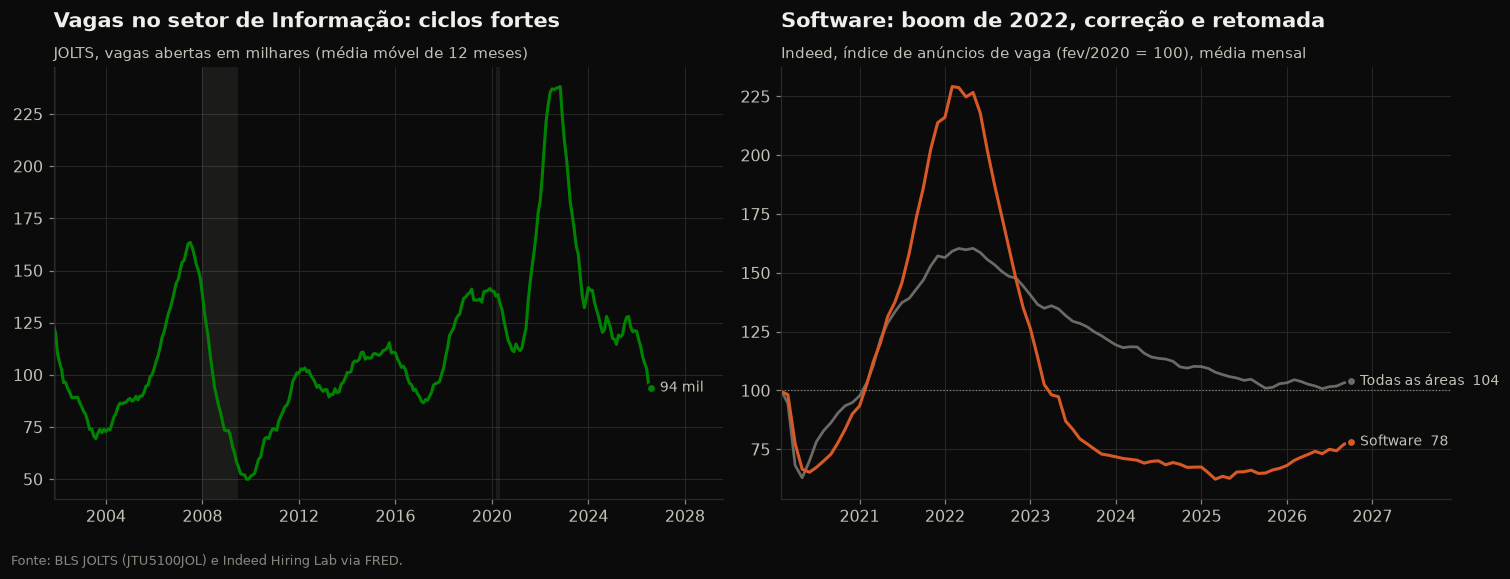

Software (Indeed): pico 229 em fev/2022, vale 62 em mar/2025, último 78 (+26% desde o vale)


In [4]:
jolts = panel["JTU5100JOL"].dropna().rolling(12).mean().dropna()
indeed_soft = panel["IHLIDXUSTPSOFTDEVE"].dropna()
indeed_all = panel["IHLIDXUS"].dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
shade_recessions(ax1)
ax1.plot(jolts.index, jolts, color=style.color_for("Setor de Informação"))
style.label_line_end(ax1, jolts.index[-1], jolts.iloc[-1], f"{jolts.iloc[-1]:.0f} mil", style.color_for("Setor de Informação"))
ax1.set_title("Vagas no setor de Informação: ciclos fortes")
style.subtitle(ax1, "JOLTS, vagas abertas em milhares (média móvel de 12 meses)")
ax1.set_xlim(jolts.index[0], jolts.index[-1] + pd.DateOffset(years=3))

ax2.axhline(100, color=style.TEXT_MUTED, lw=0.8, ls=":")
ax2.plot(indeed_all.index, indeed_all, color=style.NEUTRAL, lw=1.8)
ax2.plot(indeed_soft.index, indeed_soft, color=style.color_for("Software"))
style.label_line_end(ax2, indeed_all.index[-1], indeed_all.iloc[-1], f"Todas as áreas  {indeed_all.iloc[-1]:.0f}", style.NEUTRAL)
style.label_line_end(ax2, indeed_soft.index[-1], indeed_soft.iloc[-1], f"Software  {indeed_soft.iloc[-1]:.0f}",
                     style.color_for("Software"))
ax2.set_title("Software: boom de 2022, correção e retomada")
style.subtitle(ax2, "Indeed, índice de anúncios de vaga (fev/2020 = 100), média mensal")
ax2.set_xlim(indeed_soft.index[0], indeed_soft.index[-1] + pd.DateOffset(months=14))
style.source(fig, "BLS JOLTS (JTU5100JOL) e Indeed Hiring Lab via FRED.")
fig.tight_layout()
style.save(fig, "02_03_sinais_de_vagas")
plt.show()

vale = indeed_soft.loc["2024":].idxmin()
print(f"Software (Indeed): pico {indeed_soft.max():.0f} em {style.fmt_month(indeed_soft.idxmax())}, "
      f"vale {indeed_soft.loc[vale]:.0f} em {style.fmt_month(vale)}, último {indeed_soft.iloc[-1]:.0f} "
      f"({(indeed_soft.iloc[-1] / indeed_soft.loc[vale] - 1) * 100:+.0f}% desde o vale)")

## 4. O padrão é global? Vagas tech em 6 países

Cada painel mostra as 4 áreas de tecnologia do Indeed contra a **mediana de todas as outras áreas**
(linha cinza) do mesmo país. Média móvel de 28 dias para remover ruído semanal.

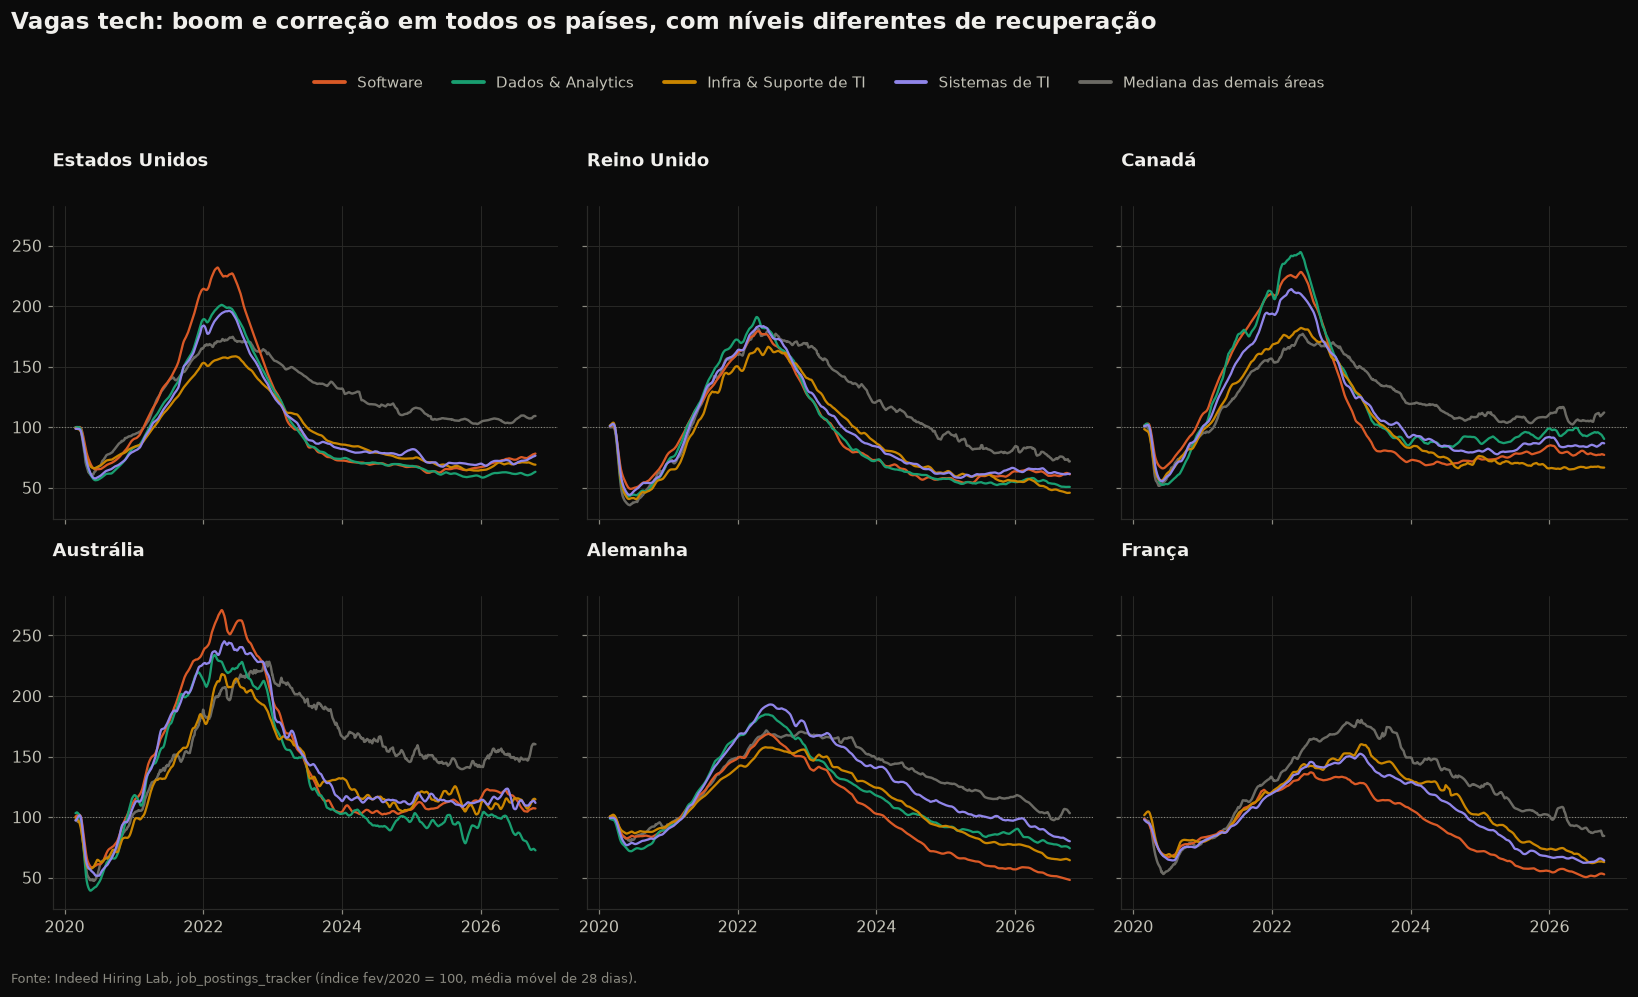

In [5]:
indeed = ds.fetch_indeed_all_countries()
indeed = indeed[indeed["variable"] == "total postings"]
nomes = {"Software Development": "Software", "Data & Analytics": "Dados & Analytics",
         "IT Infrastructure, Operations & Support": "Infra & Suporte de TI", "IT Systems & Solutions": "Sistemas de TI"}
paises = {"US": "Estados Unidos", "GB": "Reino Unido", "CA": "Canadá", "AU": "Austrália", "DE": "Alemanha", "FR": "França"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8.4), sharex=True, sharey=True)
for ax, (cc, nome_pais) in zip(axes.flat, paises.items()):
    d = indeed[indeed.jobcountry == cc]
    wide = d.pivot_table(index="date", columns="sector", values="index").rolling(28).mean()
    outros = wide.drop(columns=[c for c in config.TECH_SECTORS if c in wide]).median(axis=1)
    ax.axhline(100, color=style.TEXT_MUTED, lw=0.7, ls=":")
    ax.plot(outros.index, outros, color=style.NEUTRAL, lw=1.6)
    for sec in config.TECH_SECTORS:
        if sec in wide:
            ax.plot(wide.index, wide[sec], color=style.color_for(nomes[sec]), lw=1.5)
    ax.set_title(nome_pais, fontsize=12)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

handles = [plt.Line2D([], [], color=style.color_for(n), lw=2.5) for n in nomes.values()]
handles.append(plt.Line2D([], [], color=style.NEUTRAL, lw=2.5))
fig.legend(handles, [*nomes.values(), "Mediana das demais áreas"], loc="upper center", ncol=5,
           bbox_to_anchor=(0.5, 0.965), fontsize=10)
fig.suptitle("Vagas tech: boom e correção em todos os países, com níveis diferentes de recuperação",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=style.TEXT_PRIMARY, y=1.02)
style.source(fig, "Indeed Hiring Lab, job_postings_tracker (índice fev/2020 = 100, média móvel de 28 dias).")
fig.tight_layout(rect=(0, 0, 1, 0.93))
style.save(fig, "02_04_vagas_tech_paises")
plt.show()

## 5. Europa: especialistas em TIC (Eurostat)

O Eurostat mede **pessoas empregadas como especialistas em TIC** em todas as indústrias —
não só nas empresas de tecnologia. É a visão mais ampla da força de trabalho tech.

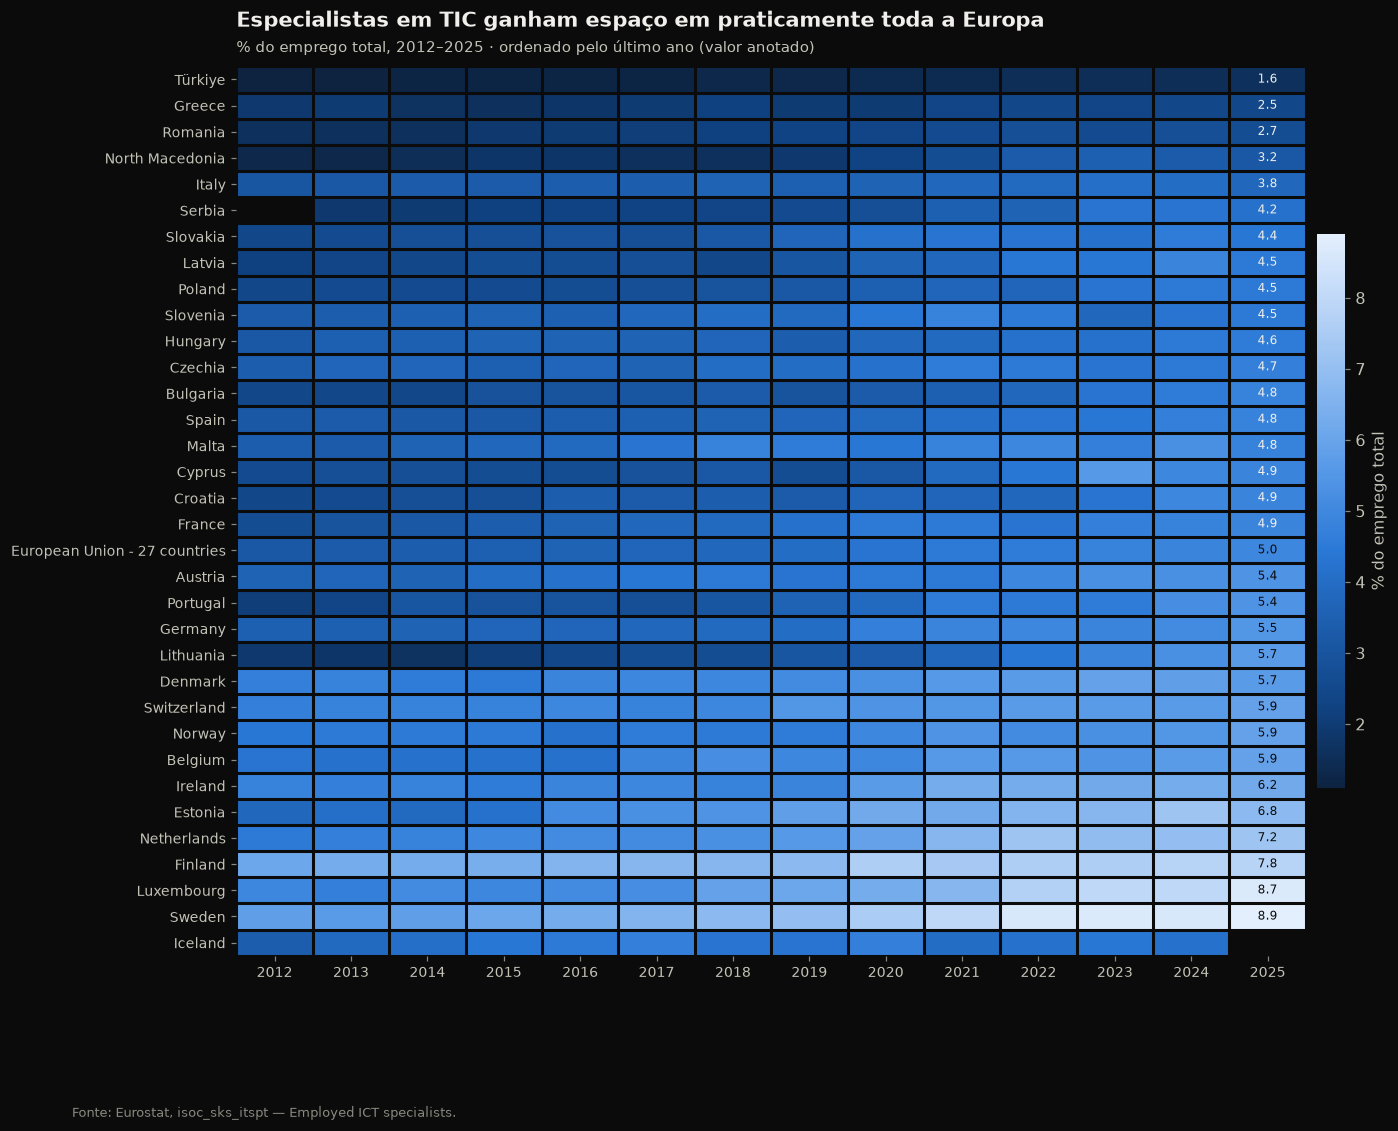

32 de 32 países/agrupamentos aumentaram a participação de 2012 a 2025.
UE-27: 5.940 mil → 10.451 mil especialistas (+76%)


In [6]:
eu = ds.fetch_eurostat_ict()
pc = eu[eu.unit == "PC_EMP"].pivot(index="geo_name", columns="time", values="value")
pc = pc.loc[:, 2012:].dropna(thresh=10)
pc.index = pc.index.str.replace(r" \(.*\)", "", regex=True)
pc = pc.sort_values(pc.columns[-1], ascending=True)

cmap = LinearSegmentedColormap.from_list("seq", style.SEQUENTIAL_BLUE)
fig, ax = plt.subplots(figsize=(13, 10.5))
im = ax.imshow(pc.values, aspect="auto", cmap=cmap, interpolation="nearest")
ax.set_yticks(range(len(pc)), pc.index, fontsize=9)
ax.set_xticks(range(len(pc.columns)), pc.columns, fontsize=9)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_xticks(np.arange(-.5, len(pc.columns)), minor=True)
ax.set_yticks(np.arange(-.5, len(pc)), minor=True)
ax.grid(which="minor", color=style.SURFACE, lw=2)
ax.tick_params(which="minor", length=0)
ultimo = pc.columns[-1]
for i, v in enumerate(pc[ultimo]):
    if pd.notna(v):
        ax.text(len(pc.columns) - 1, i, f"{v:.1f}", ha="center", va="center", fontsize=8,
                color=style.SURFACE if v > np.nanpercentile(pc.values, 75) else style.TEXT_PRIMARY)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
cb.outline.set_visible(False)
cb.set_label("% do emprego total", color=style.TEXT_SECONDARY)
ax.set_title("Especialistas em TIC ganham espaço em praticamente toda a Europa")
style.subtitle(ax, f"% do emprego total, 2012–{ultimo} · ordenado pelo último ano (valor anotado)")
style.source(fig, "Eurostat, isoc_sks_itspt — Employed ICT specialists.")
style.save(fig, "02_05_europa_heatmap")
plt.show()

delta = (pc[ultimo] - pc[2012]).dropna()
print(f"{(delta > 0).sum()} de {len(delta)} países/agrupamentos aumentaram a participação de 2012 a {ultimo}.")
eu27 = eu[(eu.geo == "EU27_2020") & (eu.unit == "THS_PER")].set_index("time")["value"]
print(f"UE-27: {style.fmt_num(eu27.loc[2012])} mil → {style.fmt_num(eu27.iloc[-1])} mil especialistas (+{(eu27.iloc[-1] / eu27.loc[2012] - 1) * 100:.0f}%)")

## 6. Distribuição do crescimento anual por década

Quão comum é o emprego tech encolher? Cada ponto é um mês (variação contra 12 meses antes).

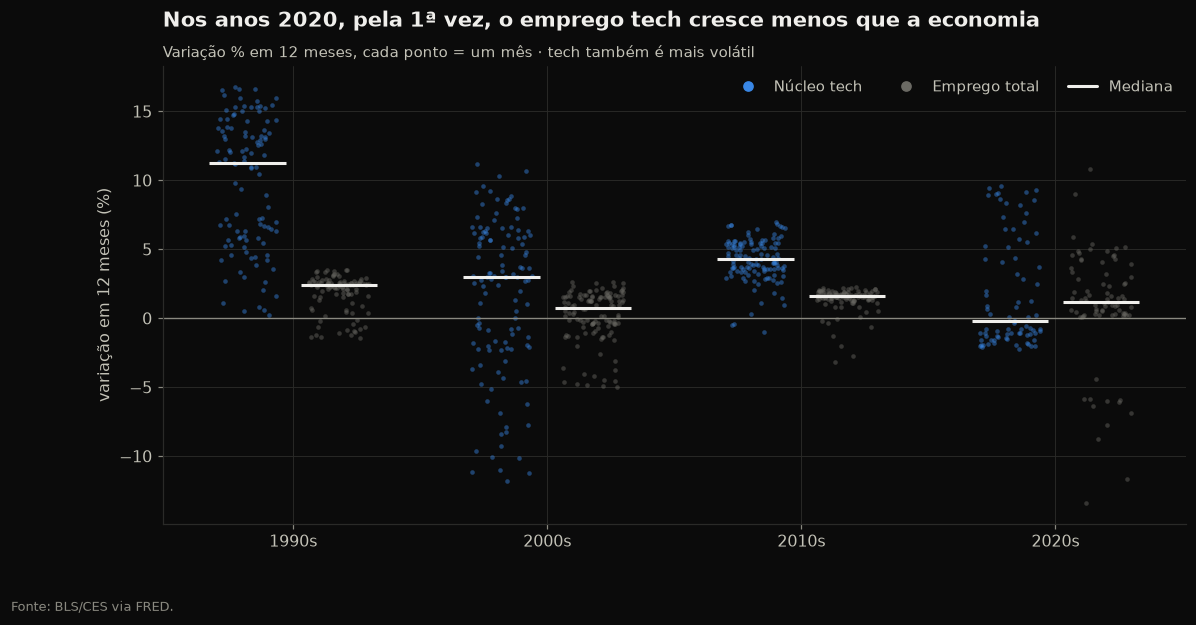

mediana                    desvio             meses_negativos  \
série  Emprego total Núcleo tech Emprego total Núcleo tech   Emprego total   
década                                                                       
1990s            2.4        11.3           1.3         4.7            13.9   
2000s            0.8         3.0           1.9         5.6            40.8   
2010s            1.6         4.3           0.9         1.5             6.7   
2020s            1.2        -0.2           4.1         3.9            14.8   

                    
série  Núcleo tech  
década              
1990s          0.0  
2000s         36.7  
2010s          2.5  
2020s         51.9

In [7]:
g_tech = ft.yoy(tech).dropna()
g_total = ft.yoy(panel["PAYEMS"].loc["1990":]).dropna()
decada = lambda s: (s.index.year // 10 * 10).astype(str) + "s"
df = pd.concat([
    pd.DataFrame({"yoy": g_tech, "série": "Núcleo tech", "década": decada(g_tech)}),
    pd.DataFrame({"yoy": g_total, "série": "Emprego total", "década": decada(g_total)}),
])

ordem = sorted(df["década"].unique())
fig, ax = plt.subplots(figsize=(12, 5.4))
rng = np.random.default_rng(42)
for j, serie in enumerate(["Núcleo tech", "Emprego total"]):
    cor = style.color_for(serie) if serie == "Núcleo tech" else style.NEUTRAL
    for i, dec in enumerate(ordem):
        v = df[(df["série"] == serie) & (df["década"] == dec)]["yoy"]
        x = i + (j - 0.5) * 0.36
        ax.scatter(x + rng.uniform(-0.12, 0.12, len(v)), v, s=9, color=cor, alpha=0.45, lw=0)
        ax.hlines(v.median(), x - 0.15, x + 0.15, color=style.TEXT_PRIMARY, lw=2)
ax.axhline(0, color=style.TEXT_MUTED, lw=0.9)
ax.set_xticks(range(len(ordem)), ordem)
ax.set_ylabel("variação em 12 meses (%)")
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=style.color_for("Núcleo tech")),
                   plt.Line2D([], [], marker="o", ls="", color=style.NEUTRAL),
                   plt.Line2D([], [], color=style.TEXT_PRIMARY, lw=2)],
          labels=["Núcleo tech", "Emprego total", "Mediana"], loc="upper right", ncol=3)
ax.set_title("Nos anos 2020, pela 1ª vez, o emprego tech cresce menos que a economia")
style.subtitle(ax, "Variação % em 12 meses, cada ponto = um mês · tech também é mais volátil")
style.source(fig, "BLS/CES via FRED.")
style.save(fig, "02_06_distribuicao_crescimento")
plt.show()

resumo = df.groupby(["década", "série"])["yoy"].agg(mediana="median", desvio="std",
                                                     meses_negativos=lambda s: (s < 0).mean() * 100).unstack()
resumo.round(1)

## Principais achados da EDA

O texto abaixo resume números calculados nas células acima.

- **Estrutural:** o núcleo tech dos EUA multiplicou o emprego por ~4,5 desde 1990 contra ~1,4 da economia,
  e sua participação no emprego total triplicou.
- **Ciclo atual:** desde o pico pós-pandemia o emprego tech recua — o mais longo período de queda desde a bolha .com.
  Anúncios de vaga de software caíram mais de 70% do pico de 2022, mas **voltaram a subir desde 2025**.
- **Global:** o mesmo boom-correção aparece em 6 países do Indeed; na Europa, a participação de especialistas em TIC
  subiu de forma quase universal entre 2012 e o último ano disponível.
- **Década de 2020 atípica:** pela primeira vez a mediana do crescimento tech (≈ −0,2% a.a.) fica abaixo da economia
  (≈ +1,2%), com mais da metade dos meses em queda — reflexo da correção pós-boom.
- **Volatilidade:** tech cresce mais, mas oscila mais. Isso exige modelos que separem **tendência** de **ciclo** —
  tarefa do notebook 03.